# Deep Learning Systems: a CNN experiment on Oxford-IIIT Pet

**Task:** classify `37` cat and dog breeds from `7,349` photos (`3,680` trainval, `3,669` test) with a convolutional neural network (CNN) on the public Oxford-IIIT Pet dataset (Oxford VGG, CC BY-SA), loaded via `torchvision.datasets.OxfordIIITPet`.

**Comparison:** a 2-block CNN trained from scratch against a ResNet18 pretrained on ImageNet and fine-tuned.

**Held fixed:** `224` px input, the stratified split (`3,129`/`551`/`3,669`), the same augmentation, optimizer, scheduler, and early-stopping rule, and a single disclosed seed.

**Research question:** how much does ImageNet pretraining improve fine-grained pet-breed classification?


## How this notebook is organised

- setup and data
- dataset inspection
- Baseline CNN
- the controlled comparison (transfer learning)
- evaluation on the test set
- how to run
- summary


### Imports and the shared seed

In [1]:
# imports and the one disclosed seed (SEED=42)
import copy
import random
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.models import resnet18, ResNet18_Weights

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device", device)


torch 2.11.0+cu128 | device cuda


### Load Oxford-IIIT Pet

In [2]:
import os
from pathlib import Path
DATA_ROOT = Path('data')
print('DATA_ROOT', DATA_ROOT, 'exists', DATA_ROOT.exists())
if (DATA_ROOT / 'oxford-iiit-pet' / 'images').exists():
    print('found', DATA_ROOT / 'oxford-iiit-pet' / 'images', 'with', len(list((DATA_ROOT / 'oxford-iiit-pet' / 'images').iterdir())), 'files')
else:
    print('data not yet present -- first run will download ~811 MB to', DATA_ROOT)

IMG_SIZE = 224
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
train_aug = datasets.OxfordIIITPet(root=str(DATA_ROOT), split='trainval', transform=train_tf, download=True)
trainval = datasets.OxfordIIITPet(root=str(DATA_ROOT), split='trainval', transform=eval_tf, download=True)
test_ds = datasets.OxfordIIITPet(root=str(DATA_ROOT), split='test', transform=eval_tf, download=True)
class_names = trainval.classes
print('trainval', len(trainval), '| test', len(test_ds), '| classes', len(class_names))
print('total', len(trainval) + len(test_ds), '-- expected 7349')

# report figures: the two figure cells write here
os.makedirs("figures", exist_ok=True)


DATA_ROOT data exists True
found data\oxford-iiit-pet\images with 7393 files
trainval 3680 | test 3669 | classes 37
total 7349 -- expected 7349


### Inspect breeds and image counts

In [3]:
# torchvision 0.26.0 exposes labels via public .targets; fall back to private _labels for older builds
labels = np.array(trainval.targets if hasattr(trainval, "targets") else trainval._labels)
counts = Counter(labels.tolist())
per_class = pd.Series({class_names[k]: counts[k] for k in sorted(counts)})
print("trainval per-class min / max:", int(per_class.min()), "/", int(per_class.max()))
per_class.sort_values().head(10)


trainval per-class min / max: 93 / 100


Egyptian Mau                  93
Bombay                        96
English Cocker Spaniel        96
Newfoundland                  96
Siamese                       99
Basset Hound                 100
American Pit Bull Terrier    100
Beagle                       100
Birman                       100
Bengal                       100
dtype: int64

### Look at sample images

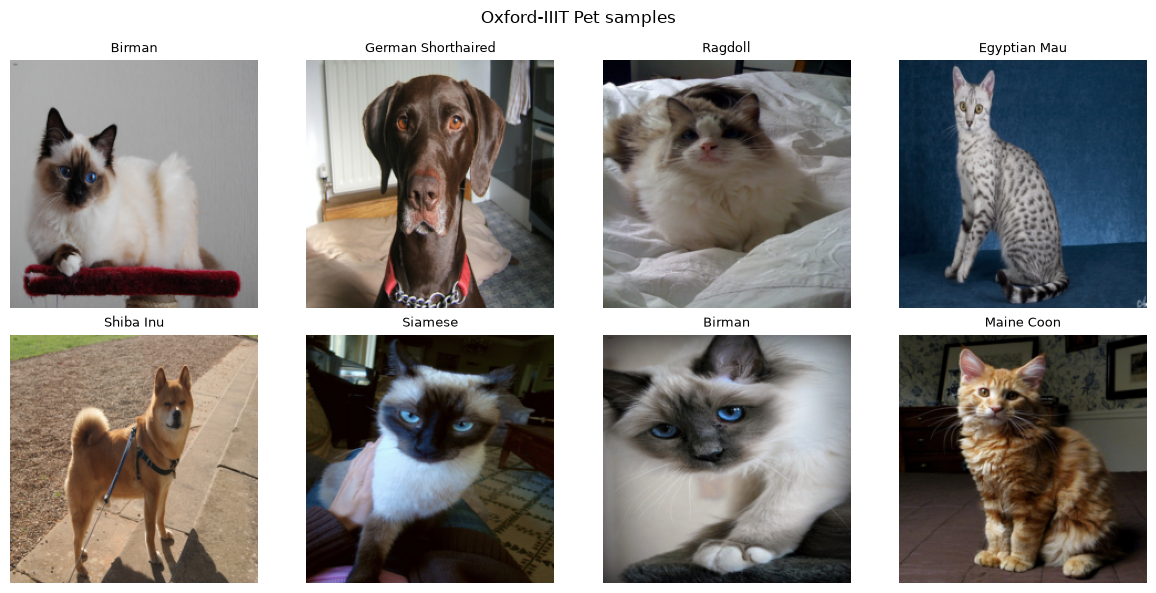

In [4]:
# define and draw an 8-image sample grid
def show_samples(ds, n=8, title="samples"):
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    idx = np.random.default_rng(SEED).choice(len(ds), n, replace=False)
    for ax, i in zip(axes.ravel(), idx):
        img, y = ds[int(i)]
        img = img.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)
        ax.imshow(np.clip(img, 0, 1))
        ax.set_title(class_names[y], fontsize=9)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_samples(trainval, title="Oxford-IIIT Pet samples")


### Stratified train/val split

In [5]:
# stratify trainval into train/val and build the three DataLoaders
def stratified_split(labels, val_frac=0.15, seed=SEED):
    rng = np.random.default_rng(seed)
    tr, va = [], []
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        rng.shuffle(idx)
        n_val = int(round(len(idx) * val_frac))
        va.extend(idx[:n_val])
        tr.extend(idx[n_val:])
    return np.array(sorted(tr)), np.array(sorted(va))

tr_idx, va_idx = stratified_split(labels)
train_ds = Subset(train_aug, tr_idx)
val_ds = Subset(trainval, va_idx)

BATCH = 64
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH, shuffle=False, num_workers=0)
print("train", len(train_ds), "| val", len(val_ds), "| test", len(test_ds))


train 3129 | val 551 | test 3669


**Split:** A 15% breed-stratified holdout produces 3,129 training and 551 validation images from 3,680 trainval images. Each breed has 93 to 100 trainval images.

**Preprocessing:** Images are resized to 224 px and normalized with ImageNet statistics.

**Augmentation:** RandomResizedCrop and horizontal flip are applied to training images only.


### Check one training batch

In [6]:
# one batch: expected shapes (64, 3, 224, 224) and (64,)
xb, yb = next(iter(train_loader))
print("batch images", tuple(xb.shape), "| batch labels", tuple(yb.shape))
print("image dtype", xb.dtype, "| label dtype", yb.dtype)


batch images (64, 3, 224, 224) | batch labels (64,)
image dtype torch.float32 | label dtype torch.int64


**Data composition reading:** No breed dominates the training pool, and the number of images per breed is fairly balanced. The breeds inside each species look alike, so the model must rely on small local details such as head shape and coat texture.

## Baseline CNN

**Architecture:** Two conv blocks (Conv2d + BatchNorm2d + ReLU + MaxPool2d) feed a dense head with Dropout that outputs 37 class scores.

**Training:** CrossEntropyLoss with Adam.

**Role:** The from-scratch reference for the comparison that follows, trained on the same 3,129 images.


### Baseline CNN: two conv blocks

In [7]:
# baseline architecture: two conv blocks + dense head
class BaselineCNN(nn.Module):
    def __init__(self, n_classes=37):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

print("baseline output shape", tuple(BaselineCNN()(xb).shape))


baseline output shape (64, 37)


### Shared training loop

In [8]:
# shared training routine: epochs, scheduler, early stopping, best state
def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train() if train else model.eval()
    total = correct = 0
    loss_sum = 0.0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            if train:
                optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            if train:
                loss.backward()
                optimizer.step()
            loss_sum += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            total += xb.size(0)
    return loss_sum / total, correct / total


def train_model(model, epochs=30, lr=1e-3, patience=5, param_groups=None):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    if param_groups is not None:
        optimizer = torch.optim.Adam(param_groups)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val = float("inf")
    best_state = None
    best_epoch = None
    wait = 0
    for epoch in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        scheduler.step(vl)
        hist["train_loss"].append(tl); hist["train_acc"].append(ta)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        print(f"epoch {epoch}: train_loss {tl:.4f} train_acc {ta:.4f} val_loss {vl:.4f} val_acc {va:.4f}")
        if vl < best_val:
            best_val = vl
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping at epoch {epoch} (best epoch {best_epoch}, best val_loss {best_val:.4f})")
                break
    if best_state is not None:
        model.load_state_dict(best_state)
        hist["best_epoch"] = best_epoch
        hist["best_val_loss"] = best_val
    return hist
# scheduler (factor 0.5, patience 2) and early stopping (patience 5) both watch val_loss
# augmentation pipeline is shared; realized draws differ under the single seed


### Train the baseline

In [9]:
# train the baseline for 30 epochs under the shared seed
EPOCHS = 30
baseline = BaselineCNN()
t0 = time.time()
hist_baseline = train_model(baseline, EPOCHS)
print("baseline train time (s):", round(time.time() - t0, 1))
print(f"baseline best epoch {hist_baseline.get('best_epoch')} with val_loss {hist_baseline.get('best_val_loss'):.4f}")


epoch 1: train_loss 3.5413 train_acc 0.0620 val_loss 3.4048 val_acc 0.1198


epoch 2: train_loss 3.3186 train_acc 0.0984 val_loss 3.2767 val_acc 0.1034


epoch 3: train_loss 3.1638 train_acc 0.1310 val_loss 3.1461 val_acc 0.1615


epoch 4: train_loss 3.0729 train_acc 0.1528 val_loss 3.0702 val_acc 0.1343


epoch 5: train_loss 2.9899 train_acc 0.1659 val_loss 2.9900 val_acc 0.1615


epoch 6: train_loss 2.9046 train_acc 0.1895 val_loss 2.9860 val_acc 0.1652


... (20 outputs left out)

epoch 27: train_loss 2.0193 train_acc 0.4043 val_loss 2.5792 val_acc 0.2958


epoch 28: train_loss 1.9766 train_acc 0.4241 val_loss 2.6726 val_acc 0.2523


epoch 29: train_loss 1.9685 train_acc 0.4215 val_loss 2.7185 val_acc 0.2632


epoch 30: train_loss 1.9745 train_acc 0.4203 val_loss 2.5822 val_acc 0.2813
baseline train time (s): 549.7
baseline best epoch 27 with val_loss 2.5792


### Baseline training curves

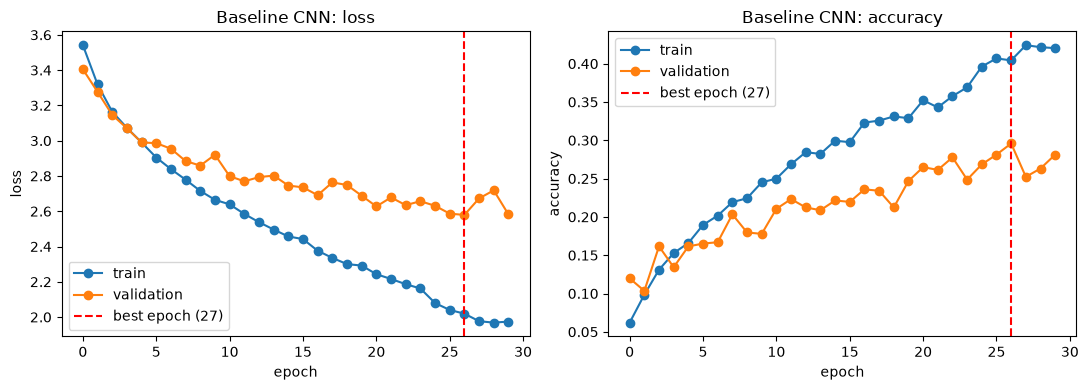

In [10]:
# plot the baseline curves with the best-epoch marker
def plot_curves(hist, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(hist["train_loss"], marker="o", label="train")
    axes[0].plot(hist["val_loss"], marker="o", label="validation")
    if "best_epoch" in hist:
        axes[0].axvline(hist["best_epoch"] - 1, color="red", linestyle="--", label=f"early stop ({hist['best_epoch']})" if len(hist["val_loss"]) < EPOCHS else f"best epoch ({hist['best_epoch']})")
    axes[0].set_title(title + ": loss"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend()
    axes[1].plot(hist["train_acc"], marker="o", label="train")
    axes[1].plot(hist["val_acc"], marker="o", label="validation")
    if "best_epoch" in hist:
        axes[1].axvline(hist["best_epoch"] - 1, color="red", linestyle="--", label=f"early stop ({hist['best_epoch']})" if len(hist["val_loss"]) < EPOCHS else f"best epoch ({hist['best_epoch']})")
    axes[1].set_title(title + ": accuracy")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].legend()
    plt.tight_layout(); plt.show()

plot_curves(hist_baseline, "Baseline CNN")


**Baseline curves reading:** Training accuracy ends at 0.4203 while validation accuracy sits at 0.2813, and validation loss bottoms at 2.5792 on epoch 27 before wobbling. The red line marks the best epoch; the run itself lasted all 30, so the marker is not an early stop.

## The controlled comparison (transfer learning)

**Changed:** One training-strategy aspect, pretraining: a ResNet18 with ImageNet weights is fine-tuned against the same 2-block baseline trained from scratch (backbone at 1e-4, head at 1e-3; He et al., 2015; Yosinski et al., 2014).

**Held fixed:** Split, augmentation pipeline, loss, optimizer, scheduler, early stopping, and the single seed.

**Adjudication:** The held-out test set. Realized augmentation draws differ under one seed and are disclosed in the outputs.


### ResNet from ImageNet, fine-tuned

In [11]:
# resnet18 with imagenet-pretrained weights, downloaded once (~45 MB) and cached
weights = ResNet18_Weights.DEFAULT
resnet = resnet18(weights=weights)
resnet.fc = nn.Linear(resnet.fc.in_features, 37)
print("resnet fc", resnet.fc)
print("resnet output shape", tuple(resnet(xb).shape))
print("preprocessing: ImageNet mean/std at 224 px, consistent with the pretrained weights")

# fine-tune strategy: backbone at 1e-4, new fc head at 1e-3
# pretrained features only need small updates; the randomly initialized head needs larger steps
backbone_params = [p for n, p in resnet.named_parameters() if not n.startswith("fc.")]
head_params = list(resnet.fc.parameters())
param_groups = [{"params": backbone_params, "lr": 1e-4}, {"params": head_params, "lr": 1e-3}]
t0 = time.time()
hist_resnet = train_model(resnet, EPOCHS, param_groups=param_groups)
print("resnet train time (s):", round(time.time() - t0, 1))
print(f"resnet best epoch {hist_resnet.get('best_epoch')} with val_loss {hist_resnet.get('best_val_loss'):.4f}")


resnet fc Linear(in_features=512, out_features=37, bias=True)


resnet output shape (64, 37)
preprocessing: ImageNet mean/std at 224 px, consistent with the pretrained weights


epoch 1: train_loss 1.5157 train_acc 0.6568 val_loss 0.4791 val_acc 0.8984


epoch 2: train_loss 0.3237 train_acc 0.9310 val_loss 0.3319 val_acc 0.9038


epoch 3: train_loss 0.1558 train_acc 0.9677 val_loss 0.3024 val_acc 0.8984


epoch 4: train_loss 0.0883 train_acc 0.9847 val_loss 0.2582 val_acc 0.9274


... (5 outputs left out)

epoch 10: train_loss 0.0092 train_acc 0.9997 val_loss 0.2430 val_acc 0.9183


epoch 11: train_loss 0.0066 train_acc 1.0000 val_loss 0.2413 val_acc 0.9201


epoch 12: train_loss 0.0053 train_acc 1.0000 val_loss 0.2445 val_acc 0.9183


epoch 13: train_loss 0.0040 train_acc 1.0000 val_loss 0.2482 val_acc 0.9274
Early stopping at epoch 13 (best epoch 8, best val_loss 0.2321)
resnet train time (s): 244.8
resnet best epoch 8 with val_loss 0.2321


### Validation curves: both models

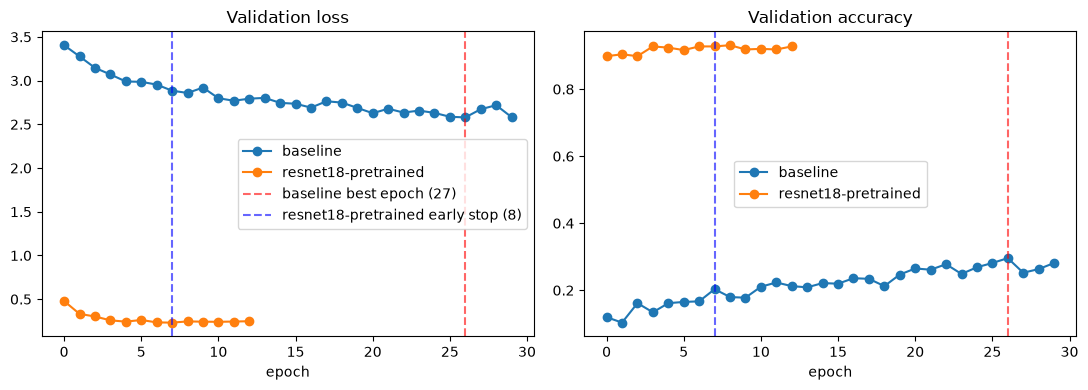

In [12]:
# combined validation curves: baseline vs pretrained
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for hist, name in [(hist_baseline, "baseline"), (hist_resnet, "resnet18-pretrained")]:
    axes[0].plot(hist["val_loss"], marker="o", label=name)
    axes[1].plot(hist["val_acc"], marker="o", label=name)
for hist, name in [(hist_baseline, "baseline"), (hist_resnet, "resnet18-pretrained")]:
    if "best_epoch" in hist:
        axes[0].axvline(hist["best_epoch"] - 1, color="red" if name == "baseline" else "blue", linestyle="--", alpha=0.6, label=f"{name} early stop ({hist['best_epoch']})" if len(hist["val_loss"]) < EPOCHS else f"{name} best epoch ({hist['best_epoch']})")
        axes[1].axvline(hist["best_epoch"] - 1, color="red" if name == "baseline" else "blue", linestyle="--", alpha=0.6)
axes[0].set_title("Validation loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].set_title("Validation accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout()
plt.savefig("figures/figure-1-validation-curves.png", dpi=110, bbox_inches="tight")
plt.show()


**Comparison reading:** the curves start out far apart and stay that way. The pretrained model opens at 0.8984 validation accuracy in epoch 1, while the baseline starts at 0.1198 and validates between 0.21 and 0.28 for the entire run. The early-stop marker is drawn for both curves, but only the pretrained one actually stopped.

### Predictions on the held-out test set

In [13]:
# predictions on the held-out test set for both models
def predict(model, loader):
    model.eval()
    preds, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            out = model(xb.to(device))
            preds.append(out.argmax(1).cpu())
            ys.append(yb)
    return torch.cat(preds).numpy(), torch.cat(ys).numpy()

pred_b, y_true = predict(baseline, test_loader)
pred_r, _ = predict(resnet, test_loader)
acc_b = float((pred_b == y_true).mean())
acc_r = float((pred_r == y_true).mean())
print(f"test accuracy: baseline {acc_b:.4f} | resnet18-pretrained {acc_r:.4f}")
print(f"baseline train-val acc gap (last epoch): {hist_baseline['train_acc'][-1] - hist_baseline['val_acc'][-1]:.4f}")
print(f"resnet   train-val acc gap (last epoch): {hist_resnet['train_acc'][-1] - hist_resnet['val_acc'][-1]:.4f}")


test accuracy: baseline 0.2044 | resnet18-pretrained 0.8940
baseline train-val acc gap (last epoch): 0.1390
resnet   train-val acc gap (last epoch): 0.0726


**Test numbers reading:** The difference is the whole finding: from the 3,669 held-out images, the scratch baseline scores only 0.2044 against 0.8940 for the fine-tuned model. Macro per-class accuracy tracks each model raw accuracy (0.2051 and 0.8934), so neither model profits from imbalance on this balanced set. The train-validation gaps close the picture: 0.1390 for the scratch baseline, 0.0726 for the fine-tuned model.

### Confusion matrix and per-class accuracy

baseline: macro per-class accuracy 0.2051
resnet18-pretrained: macro per-class accuracy 0.8934


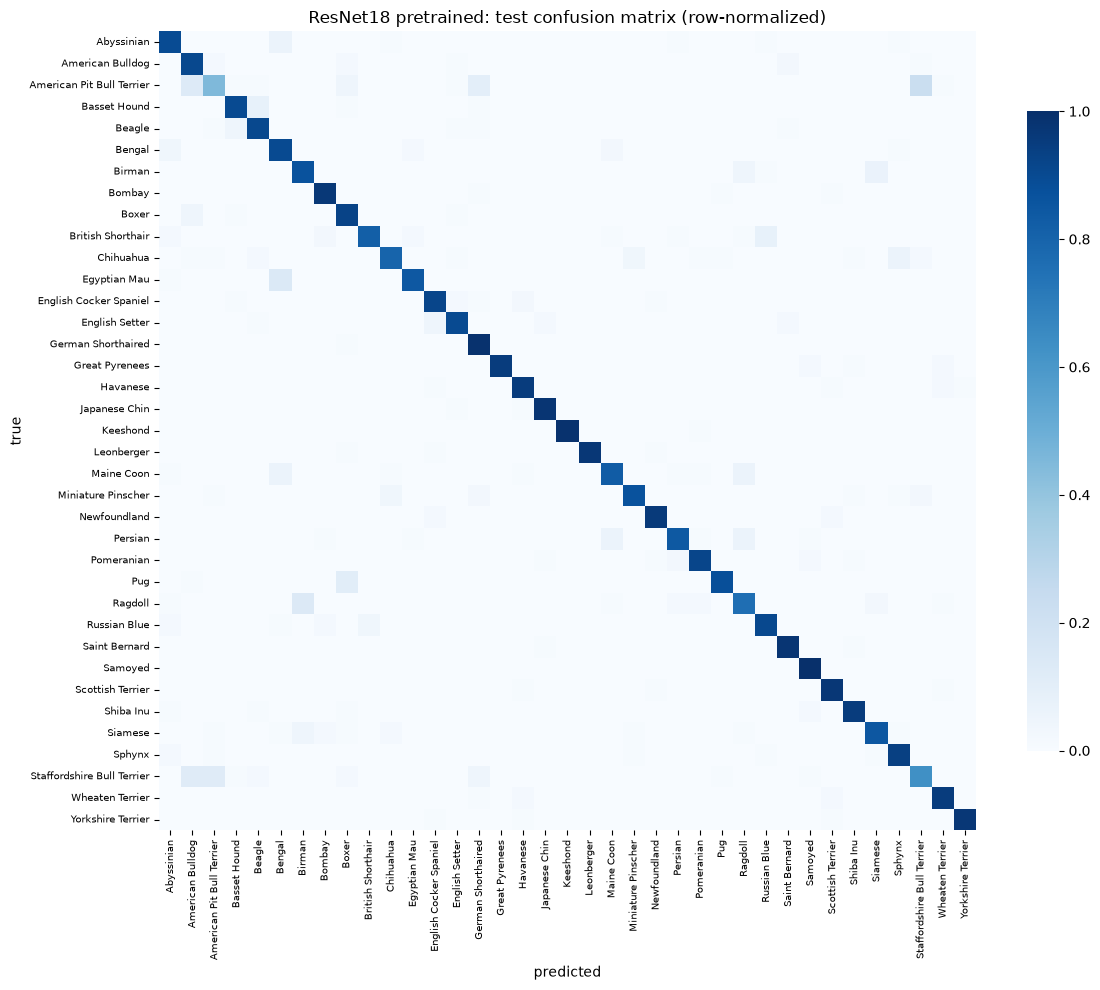

In [14]:
# resnet confusion matrix (breed-labeled); macro accuracy for both
def confusion(preds, y, n=37):
    m = np.zeros((n, n), dtype=int)
    for t, p in zip(y, preds):
        m[t, p] += 1
    return m

cm_b = confusion(pred_b, y_true)
cm_r = confusion(pred_r, y_true)
for name, m in [("baseline", cm_b), ("resnet18-pretrained", cm_r)]:
    row = m.sum(1)
    per_class_acc = np.divide(m.diagonal(), row, out=np.zeros(37), where=row > 0)
    print(name + ": macro per-class accuracy", round(float(per_class_acc.mean()), 4))

plt.figure(figsize=(12, 10))
sns.heatmap(cm_r / np.maximum(cm_r.sum(1, keepdims=True), 1), cmap="Blues",
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={"shrink": 0.8})
plt.title("ResNet18 pretrained: test confusion matrix (row-normalized)")
plt.xlabel("predicted"); plt.ylabel("true")
plt.xticks(fontsize=7, rotation=90); plt.yticks(fontsize=7)
plt.tight_layout()
plt.savefig("figures/figure-2-confusion-matrix.png", dpi=110, bbox_inches="tight")
plt.show()


**Confusion matrix reading:** the row-normalized matrix is dark on the diagonal, and its misses cluster in blocks of visually similar breeds rather than scattering at random. Faces differ between species, but within each species breeds agree in shape and coat, and that is where the errors live; the per-class table below names the worst of them.

### Misclassified examples

resnet18-pretrained misclassified: 389 of 3669


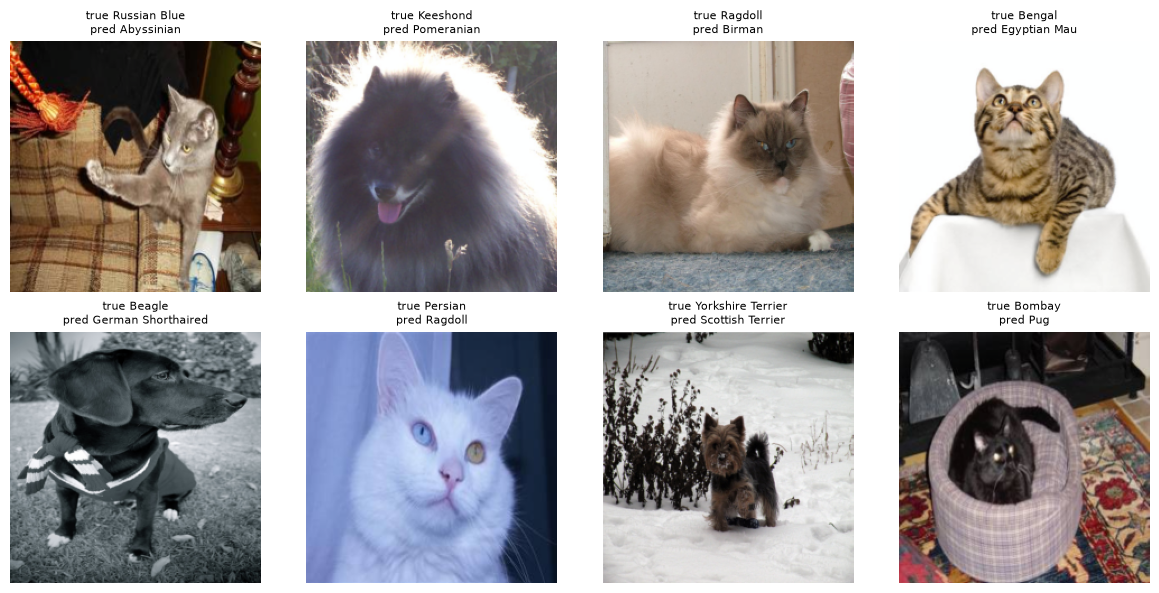

In [15]:
# error panel: 8 misclassified images across distinct breeds
mis = np.where(pred_r != y_true)[0]
print("resnet18-pretrained misclassified:", len(mis), "of", len(y_true))
rng = np.random.default_rng(SEED)
shown = []
for c in rng.permutation(np.unique(y_true[mis])):
    shown.append(int(mis[y_true[mis] == c][0]))
    if len(shown) == 8:
        break
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, i in zip(axes.ravel(), shown):
    img, y = test_ds[int(i)]
    img = img.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)
    ax.imshow(np.clip(img, 0, 1))
    ax.set_title("true " + class_names[y] + "\npred " + class_names[pred_r[i]], fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()


### Per-class accuracy table

In [16]:
# resnet per-class accuracy table (top rows, 2 decimals)
row = cm_r.sum(1)
pca_r = np.divide(cm_r.diagonal(), row, out=np.zeros(37), where=row > 0)
row = cm_b.sum(1)
pca_b = np.divide(cm_b.diagonal(), row, out=np.zeros(37), where=row > 0)
cmp = pd.DataFrame({"baseline": pca_b, "resnet18-pretrained": pca_r}, index=class_names).sort_values("resnet18-pretrained")
cmp.head(10).round(2)


,baseline,resnet18-pretrained
American Pit Bull Terrier,0.05,0.45
Staffordshire Bull Terrier,0.18,0.63
Ragdoll,0.28,0.76
Chihuahua,0.05,0.80
British Shorthair,0.27,0.82
Maine Coon,0.17,0.83
Persian,0.11,0.84
Egyptian Mau,0.37,0.85
Siamese,0.20,0.85
Birman,0.13,0.87


**Per-class table reading:** every breed in the bottom ten improves under pretraining, and the lift is largest where the scratch network was nearly blind: Chihuahua moves from 0.05 to 0.80 and Birman from 0.13 to 0.87, while American Pit Bull Terrier remains the weakest class at 0.45 among the ten shown. These are also the breeds where a mislabel has the most consequence, in adoption or veterinary settings.

## How to run

**Environment:** Python `3.13` with PyTorch `2.11.0+cu128`. The CUDA wheel index is required because `torch==2.11.0+cu128` is not on PyPI, and `uv` needs `--index-strategy unsafe-best-match` to consider both indexes at once.

```bash
uv venv --python 3.13 .venv
uv pip install --python .venv\Scripts\python.exe --extra-index-url https://download.pytorch.org/whl/cu128 --index-strategy unsafe-best-match -r requirements.txt
.venv\Scripts\python.exe -m nbconvert --to notebook --execute --inplace deep_learning.ipynb
```

**First run:** downloads Oxford-IIIT Pet (about `811` MB: `792` MB of images plus `19` MB of annotations) and unpacks it under `data/oxford-iiit-pet/` (the `torchvision` base folder is `data/`, at the repo root).

**Downloaded weights:** pretrained ResNet18 (~`45` MB) is downloaded once via `torchvision` and cached under the torch hub directory; later runs reuse both and are offline-safe. A CPU-only machine runs the same code, only slower.

Dataset access and first-run download details: `DATASET.md`.


## Summary

This notebook asks: "Can a CNN distinguish 37 cat and dog breeds from 7,349 images, with 93 to 100 trainval images per breed, and does ImageNet pretraining improve test performance?"

This question was answered by running a comparison between a 2-block CNN trained from scratch and a fine-tuned ResNet18 under the same split and training procedure; the held-out test set evaluates the final performance of both models, and the labelled fields below report its results and briefly describe the methodology.

**Validation:** Baseline best epoch 27 (val_loss 2.5792); ResNet18 stopped at epoch 13, best epoch 8 (val_loss 0.2321).

**Test:** Baseline 0.2044 (macro 0.2051); ResNet18 0.8940 (macro 0.8934), with 389 errors among 3,669 test images.

**Challenges:** the small training pool made the baseline overfit; the pretrained model relied on the early-stopping rule to stop at epoch 13; and separating visually similar breeds stayed hard for both models.

**Scope:** These results come from one stratified split; training augmentation draws differed between models.


### Reproducible headline numbers


In [17]:
# summary: headline numbers from this run (no hardcoding)
cm_b, cm_r = confusion(pred_b, y_true), confusion(pred_r, y_true)

def macro(cm):
    row = cm.sum(1)
    per_class_acc = np.divide(cm.diagonal(), row, out=np.zeros(37), where=row > 0)
    return float(per_class_acc.mean())

print("Data:      ", f"{len(trainval) + len(test_ds)} images, {len(class_names)} breeds")
print("Split:     ", f"train {len(train_ds)} / val {len(val_ds)} / test {len(test_ds)}, stratified 15%")
print("Seed:      ", SEED)
print("Models:    ", f"baseline test {acc_b:.4f}, macro {macro(cm_b):.4f}; resnet18 test {acc_r:.4f}, macro {macro(cm_r):.4f}")
print("Comparison:", f"gain {acc_r - acc_b:.4f}, misclassified {int((pred_r != y_true).sum())} of {len(y_true)} test images")


Data:       7349 images, 37 breeds
Split:      train 3129 / val 551 / test 3669, stratified 15%
Seed:       42
Models:     baseline test 0.2044, macro 0.2051; resnet18 test 0.8940, macro 0.8934
Comparison: gain 0.6896, misclassified 389 of 3669 test images
